In [109]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

#from gauss_slicer import * 

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [110]:
#import data
# step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov9th/counterrotation.fits')
# step = step[0:37] #crop off the bad results from the end of speckle 4
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov5th/counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')

In [111]:
for img in step: #the dark subtraction isn't working so i had to median subtract the image... should I do this onsky?
       img -= np.median(img)

In [112]:
len(step)

51

In [113]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,snr_threshold=2.6,speckle_window=60) 

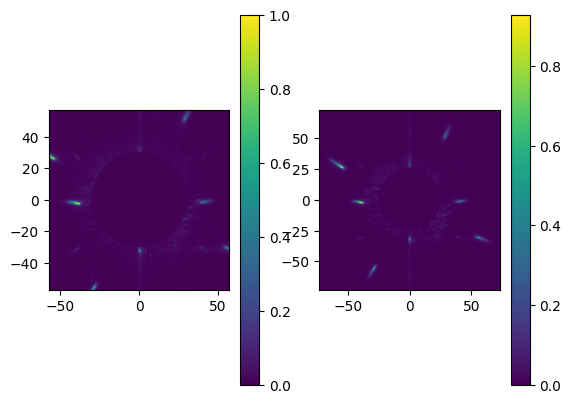

In [114]:
plt.subplot(1,2,1)
imshow_field(ADC.crop_image(step[1]))
plt.colorbar()
plt.subplot(1,2,2)
imshow_field(ADC.filter_image(ADC.crop_image(step[1],mask_diam=50,extent=512)))
plt.colorbar()

In [115]:
h = ADC.filter_image(ADC.crop_image(step[0],mask_diam=30,extent=500))
q = ADC.slice_speckle_angle(h,0,print_updates=True)

unable to fit speckle 0


/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:23: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:112: RuntimeWarning: invalid value encountered in divide
  zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)


In [96]:
#filter all the image cubes from each step
filtered_sweep = [] #filtered image cube at each step
speckle_list = [] #speckle angle list at each step

for i, field in enumerate(step):
    filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=40,extent=512)) 
    #filtered = ADC.crop_image(ADC.filter_image(field),extent=500,mask_diam=60) 
    #imshow_field(filtered)
    a = ADC.all_speckle_angles(filtered)
    speckle_list.append(a)

speckle_list = np.array(speckle_list)

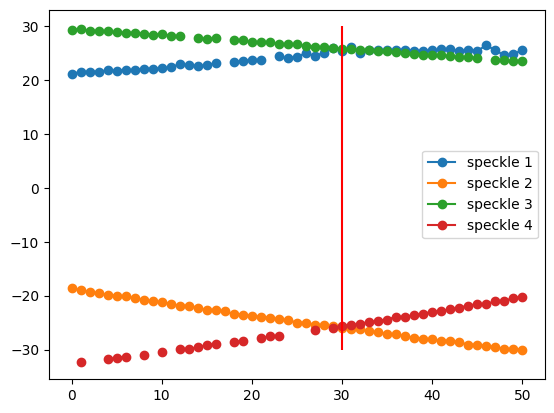

In [107]:
for i in range(4):
    plt.plot(speckle_list[:,i],'-o',label=f'speckle {i+1}')

plt.vlines(30,-30,30,colors='red')
plt.legend()

In [108]:
#find zero points to subtract (using pairs response to choose list index)
zps = speckle_list[30]
print(zps)

[ 25.47224616 -25.9758844   25.82760786 -25.5740744 ]


slope of speckle 0: 0.4884833287137673
slope of speckle 1: -1.1423039367136136
slope of speckle 2: -0.6106117228953217
slope of speckle 3: 1.2463128453709607


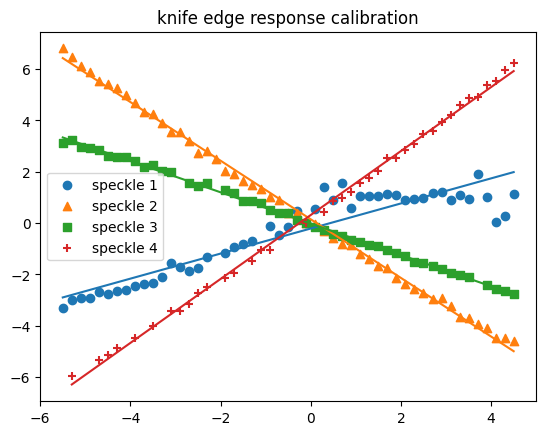

In [ ]:
#now calculate response
response = np.zeros(speckle_list.shape)
angle_offsets = np.linspace(-5,5,51) - 0.5
markers = ['o','^','s','+']
m = np.zeros(4)

for i in range(4):
    response = speckle_list[:,i] - zps[i]
    idxs = np.isfinite(response)
    plt.scatter(angle_offsets[idxs],response[idxs],marker=markers[i],label=f'speckle {i+1}')
    m[i], b = np.polyfit(angle_offsets[idxs],response[idxs],deg=1)
    print(f'slope of speckle {i}: {m[i]}')
    linepoints = b + m[i] * angle_offsets[idxs]
    plt.plot(angle_offsets[idxs], linepoints)

plt.legend()
plt.title('knife edge response calibration')
plt.show()

In [101]:
resp_top = np.matrix(np.array([m[0],m[3]])) #if you can see the speckles on the top
resp_bottom = np.matrix(np.array([m[1],m[2]])) #bottom speckles

ctrl_matrix_top = np.linalg.pinv(resp_top).T
ctrl_matrix_bottom = np.linalg.pinv(resp_bottom).T

print(f'top: {ctrl_matrix_top}')
print(f'bottom: {ctrl_matrix_bottom}')

top: [[0.27260458 0.69552136]]
bottom: [[-0.68087296 -0.36395656]]


In [102]:
#now test it on the same dataset
h1 = speckle_list[0,0] - zps[0]
h2 = speckle_list[0,3] - zps[3]

measurement = ctrl_matrix_top @ np.array([h1,h2])
print(measurement)

[[nan]]


In [103]:
#top speckles
measurements = np.zeros(len(angle_offsets))

for i in range(len(angle_offsets)):
    h1 = speckle_list[i,0] - zps[0]
    h2 = speckle_list[i,3] - zps[3]

    measurements[i] = ctrl_matrix_top @ np.array([h1,h2])

/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_8620/934641233.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  measurements[i] = ctrl_matrix_top @ np.array([h1,h2])


Text(0.5, 1.0, 'using top speckles only')

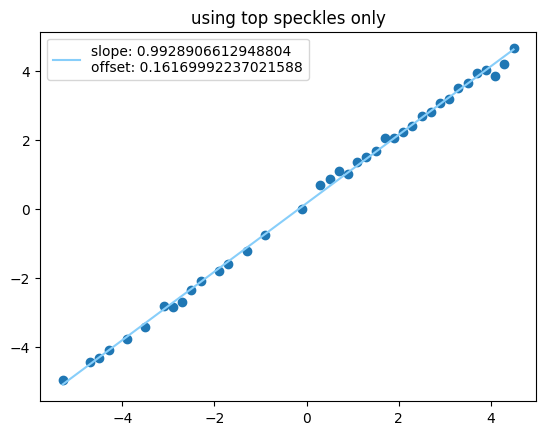

In [104]:
idxs = np.isfinite(measurements)
plt.scatter(angle_offsets[idxs],measurements[idxs])
m,b = np.polyfit(angle_offsets[idxs],measurements[idxs],deg=1)
linepoints = b + m * angle_offsets[idxs]
plt.plot(angle_offsets[idxs],linepoints,color='lightskyblue',label=f'slope: {m}\noffset: {b}')
plt.legend()
plt.title('using top speckles only')

In [105]:
#same for bottom speckles
measurements = np.zeros(len(angle_offsets))

for i in range(len(angle_offsets)):
    h1 = speckle_list[i,1] - zps[1]
    h2 = speckle_list[i,2] - zps[2]

    measurements[i] = ctrl_matrix_bottom @ np.array([h1,h2])

/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_8620/1499516882.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  measurements[i] = ctrl_matrix_bottom @ np.array([h1,h2])


Text(0.5, 1.0, 'using bottom speckles only')

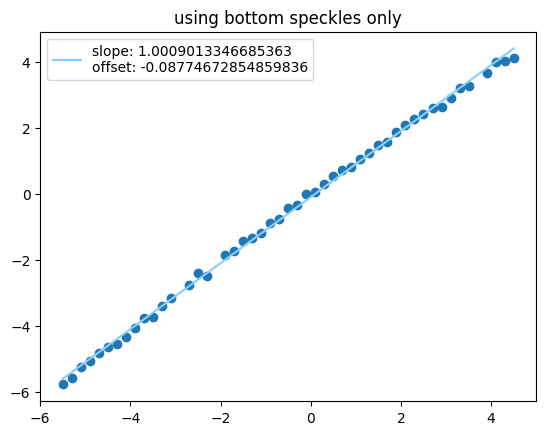

In [106]:
idxs = np.isfinite(measurements)
plt.scatter(angle_offsets[idxs],measurements[idxs])
m,b = np.polyfit(angle_offsets[idxs],measurements[idxs],deg=1)
linepoints = b + m * angle_offsets[idxs]
plt.plot(angle_offsets[idxs],linepoints,color='lightskyblue',label=f'slope: {m}\noffset: {b}')
plt.legend()
plt.title('using bottom speckles only')